In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

df=pd.read_csv("C:/Users/GISHA/Documents/MACHINE LEARNING ENGINEER/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head())

print("Shape of dataset :", df.shape)
print("Columns :", df.columns.tolist())

df.info()

df.dtypes

print(df.isnull().sum())

print(df["Churn"].value_counts())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [4]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [5]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [6]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [8]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [9]:
print(df["TotalCharges"].str.strip().eq("").sum())
print(df["TotalCharges"].head(10))

# TotalCharges is currently stored as a string (str), although it represents numerical values.

# We need to:
# 1. Identify blank strings.
# 2. Convert the column to numeric.
# 3. Handle any missing values created during conversion.
# 4. Verify the final data type.

11
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
5      820.5
6     1949.4
7      301.9
8    3046.05
9    3487.95
Name: TotalCharges, dtype: str


In [ ]:
# Blank values in TotalCharges
# 11

# Issue identified
# - Original data type: str
# - Expected data type: Numeric
# - Blank strings: 11
# - Actual NaN values before conversion: 0

# Why did isnull() show zero?
# Because an empty string ("") or whitespace is not the same as a Pandas missing value (NaN).

# This is a common real-world data-cleaning problem.

In [10]:
df["TotalCharges"]=pd.to_numeric(
    df["TotalCharges"],errors="coerce"
)

# pd.to_numeric() converts values into numerical format.
# errors="coerce" converts invalid or blank values into NaN.

# We update the original TotalCharges column.

In [12]:
print(df["TotalCharges"].dtype)


float64


In [13]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [ ]:
# Data type should become float64.
# Missing values should become 11.

In [ ]:
# Task 3: Investigate the 11 missing records

In [11]:
df[df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [ ]:
# Understanding the 11 missing records
# Look at these columns in your output:
# Column	Observation
# Missing TotalCharges	11
# tenure	0 for all 11
# MonthlyCharges	Has values
# Churn	No for all 11

# Important finding: All 11 customers have tenure = 0.

# This suggests that these customers are new customers who have not yet accumulated any monthly charges.

# Since their total charges are missing, we should investigate whether zero is the appropriate value rather than blindly deleting these records.
# 1. What should we do with these missing values?
# We have two possible approaches:
# - Delete 11 rows: We lose useful customer information.
# - Replace missing TotalCharges with 0: This is reasonable because all 11 records have zero tenure and no accumulated customer charges.
# Our decision: Replace these 11 missing values with zero, based on this business interpretation.
# 2. Perform data cleaning

In [14]:
df["TotalCharges"]=df["TotalCharges"].fillna(0)

In [16]:
print("Missing values : ", df["TotalCharges"].isnull().sum())

Missing values :  0


In [17]:
df["TotalCharges"].dtype

dtype('float64')

In [18]:
print("Duplicate rows : ", df.duplicated().sum())

Duplicate rows :  0


In [19]:
df["customerID"].duplicated().sum()

np.int64(0)

In [ ]:
# What does this mean?
# 1. No complete duplicate records exist.
# 2. Every customer ID is unique.
# 3. We don't need to remove duplicate records.

In [ ]:
# ML Engineer observation: Unique customer IDs do not mean customer IDs should be used as model features. 
# We will exclude customerID during model preparation.

In [ ]:
# Step 4 – Final data-quality verification Before starting EDA

In [20]:
df.shape

(7043, 21)

In [21]:
df.isnull().sum().sum()

np.int64(0)

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [ ]:
# Step 5 – Start Exploratory Data Analysis (EDA)

In [ ]:
# Visualization 1 – Customer Churn Distribution

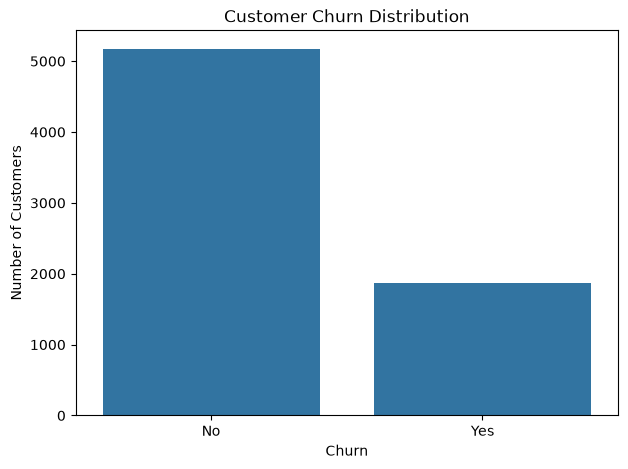

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
# - countplot() counts observations in each category.
# - X-axis represents customer churn (Yes or No).
# - Y-axis represents the number of customers.
# Business interpretation: This graph helps the company understand how many customers are leaving
# compared with those staying.

In [ ]:
# Visualization 2 – Churn based on Tenure
# We want to understand whether customers who have
# been with the company for a shorter period are more likely to leave.

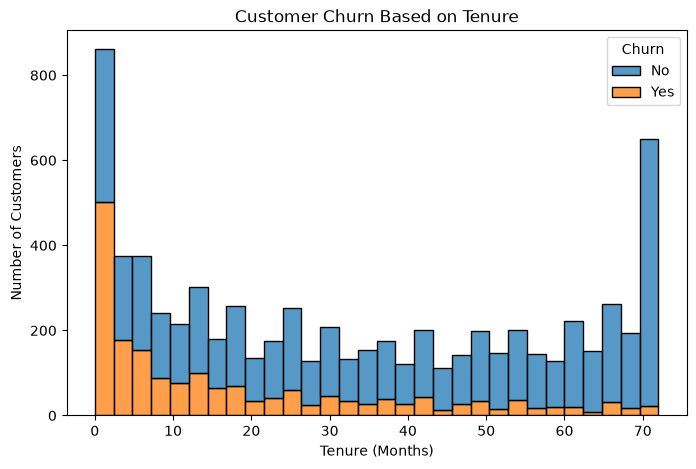

In [27]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack"
)

plt.title("Customer Churn Based on Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
# Business question: Are new customers more likely to leave than long-term customers?

In [ ]:
# Visualization 3 – Churn based on Monthly Charges

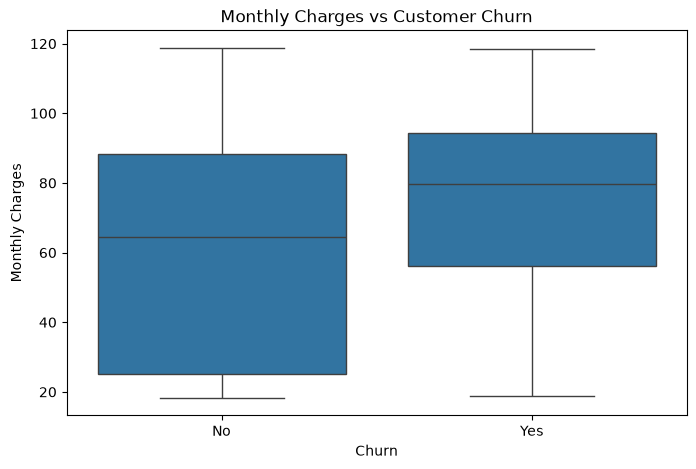

In [28]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [ ]:
# Business question: Do customers who leave tend to have different monthly charges from customers who stay?

In [ ]:
# Visualization 4 – Churn based on Contract

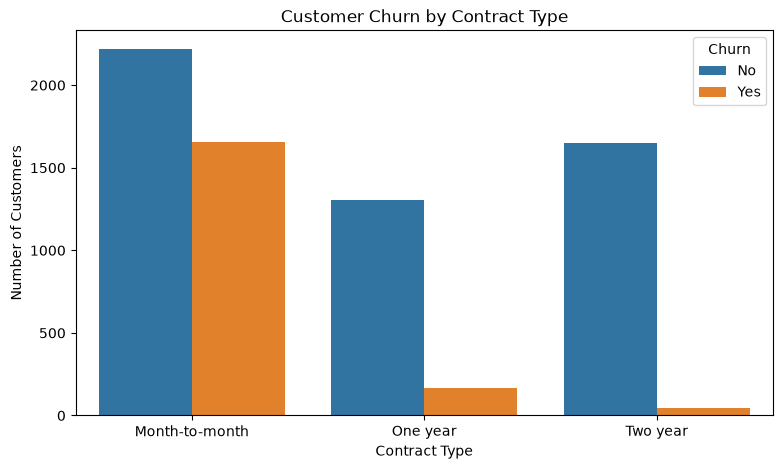

In [29]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
# Business question: Which contract category has the highest number of customers leaving?

In [ ]:
# One important rule: We won't select an algorithm just because it gives high accuracy. Our model selection will be based on the business problem, proper validation and suitable evaluation metrics.

# After EDA, we'll proceed to feature engineering, model training and deployment.

In [ ]:
FEATURE ENGINEERING

Target Encoding: Convert Churn (Yes/No) into binary values (1/0).

Categorical Encoding:

Binary columns (gender, Partner, Dependents, PhoneService, PaperlessBilling) -> Label Encoding (0/1).

Multi-category columns (InternetService, Contract, PaymentMethod, etc.) -> One-Hot Encoding (pd.get_dummies or OneHotEncoder).

Feature Scaling: Scale continuous variables like tenure, MonthlyCharges, and TotalCharges using StandardScaler so they have a mean of 0 and variance of 1.


In [1]:
pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

def preprocess_data(df):
    """Cleans the dataframe, handles missing values, and sets up the ColumnTransformer."""
    # Drop customerID as it's just a unique identifier
    if 'customerID' in df.columns:
        df = df.drop(columns=['customerID'])
        
    # Fix TotalCharges (spaces represent new customers with 0 tenure)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df['TotalCharges'] = df['TotalCharges'].fillna(0)
    
    # Convert target variable Churn to binary (1 for Yes, 0 for No)
    if 'Churn' in df.columns:
        df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
        
    # Separate features (X) and target (y)
    X = df.drop(columns=['Churn'])
    y = df['Churn']
    
    # Identify numerical and categorical columns
    numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
    categorical_features = [col for col in X.columns if col not in numeric_features]
    
    # Create preprocessing pipelines using ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
        ])
        
    return X, y, preprocessor

def main():
    print("1. Loading dataset...")
    # Load your dataset (ensure the filename matches your file)
    df = pd.read_csv("Documents/MACHINE LEARNING ENGINEER/data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
    
  
    print("2. Preprocessing data...")
    
    X, y, preprocessor = preprocess_data(df)
    
    print("3. Splitting dataset into training and testing sets (with stratification)...")
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, 
        test_size=0.2, 
        random_state=42, 
        stratify=y
    )
    
    # Define models inside pipelines combining preprocessor and classifier
    models = {
        "Logistic Regression": Pipeline([
            ('preprocessor', preprocessor), 
            ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
        ]),
        "Random Forest": Pipeline([
            ('preprocessor', preprocessor), 
            ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
        ]),
        "XGBoost": Pipeline([
            ('preprocessor', preprocessor), 
            ('classifier', XGBClassifier(eval_metric='logloss', random_state=42))
        ])
    }
    
    print("\n4. Training and Evaluating Models...")
    results = {}
    best_auc = 0.0
    best_model_name = None
    best_model_pipeline = None
    
    for name, model in models.items():
        print(f"--- Training {name} ---")
        model.fit(X_train, y_train)
        
        # Predictions
        y_pred = model.predict(X_test)
        y_proba = model.predict_proba(X_test)[:, 1]
        
        # Metrics
        auc = roc_auc_score(y_test, y_proba)
        results[name] = {"roc_auc": auc}
        
        print(f"{name} ROC-AUC: {auc:.4f}")
        print("Classification Report:")
        print(classification_report(y_test, y_pred))
        print("="*50)
        
        # Track the best model based on ROC-AUC
        if auc > best_auc:
            best_auc = auc
            best_model_name = name
            best_model_pipeline = model

    print(f"\n🏆 Best Model: {best_model_name} with ROC-AUC: {best_auc:.4f}")
    
    # Save the best performing model pipeline to disk
    model_filename = 'churn_model_pipeline.pkl'
    joblib.dump(best_model_pipeline, model_filename)
    print(f"Model successfully saved to {model_filename}")

if __name__ == "__main__":
    main()

1. Loading dataset...
2. Preprocessing data...
3. Splitting dataset into training and testing sets (with stratification)...

4. Training and Evaluating Models...
--- Training Logistic Regression ---
Logistic Regression ROC-AUC: 0.8417
Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

--- Training Random Forest ---
Random Forest ROC-AUC: 0.8222
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      1035
           1       0.56      0.64      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

--- 

In [ ]:
ColumnTransformer(...): This container holds multiple transformation pipelines and applies them in parallel to the specified subsets of columns, 
then stitches the resulting columns back together into a single unified matrix.

transformers=[...]: A list of tuples defining the transformation rules. 
    Each tuple follows the format: (name_of_step, transformer_object, list_of_columns_to_apply_it_to).

In [ ]:
'num': A custom string label you give to this specific transformation 
step (useful for debugging or accessing later).
    StandardScaler(): This standardizes numerical features so they have a
mean of 0 and a variance (standard deviation) of 1 
    
Why do this? Machine learning algorithms like Logistic Regression or Neural Networks converge 
faster and perform better when features are on the same scale (e.g., preventing MonthlyCharges 
            ranging from 20 to 120 from overshadowing tenure ranging from 0 to 72).
numeric_features: The list of column names containing 
numerical data (e.g., ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']).

In [ ]:
'cat': The name label for the categorical transformation step.

OneHotEncoder(...): Converts text or categorical categories into binary columns (0 or 1).
    For example, a column like InternetService with values DSL, Fiber optic, 
and No gets turned into separate Numeric columns.

drop='first': Drops the first binary column for each categorical feature to avoid 
    multicollinearity (the dummy variable trap). If a customer doesn't have DSL and doesn't
                        have Fiber optic, the model automatically knows they have No internet.

handle_unknown='ignore': Crucial for production/deployment. If your model encounters a brand
new category in real-world data that it never saw during training, it won't crash; 
it will simply assign all zero values to those encoded columns.

categorical_features: The list of text/categorical column names (e.g., Contract, PaymentMethod, Gender).

Why use ColumnTransformer inside a Pipeline?
By wrapping this preprocessor inside a scikit-learn Pipeline alongside your classifier, you prevent data leakage. It ensures that scaling statistics (like mean and standard deviation) are computed only on the training fold during cross-validation,
and then applied to the validation/test fold without peeking into future data.

In [ ]:
Model Training & Evaluation
Telco churn datasets are typically imbalanced (roughly 26% churned vs. 74% retained). Relying purely on accuracy can be misleading; focus on ROC-AUC, Precision, Recall, and F1-Score.

Training Strategy
Train-Test Split: Use an 80-20 split with stratification (stratify=y) to maintain the class balance.

Handling Imbalance: Use class weights (class_weight='balanced') or techniques like SMOTE (Synthetic Minority Over-sampling Technique) if necessary, though gradient boosting models (XGBoost, LightGBM) handle imbalance well with scale_pos_weight.

Model Selection: Compare Logistic Regression (baseline), Random Forest, and XGBoost.

In [ ]:
Stratification (stratify=y) is a sampling technique used when splitting your dataset into 
training and testing sets (using train_test_split) to ensure that the proportion of target 
classes remains identical in both sets.

In [ ]:
How XGBoost Works (The Magic Behind It)
XGBoost is an ensemble learning method based on decision trees.

Instead of building just one large decision tree, it builds an ensemble of shallow trees 
sequentially (one after another).

Each new tree is trained specifically to correct the errors (residuals) made by the previous trees.

It uses a technique called gradient descent to minimize a loss function, 
steadily tuning the model to make fewer mistakes with every iteration.

In [ ]:
Why XGBoost is Ideal for Churn Prediction
Handles Tabular Data Exceptionally Well: Telco churn datasets contain a mix of 
numerical features (like tenure, MonthlyCharges) and categorical features (like Contract, PaymentMethod). Tree-based models like XGBoost capture non-linear relationships between these features much better than linear models.

Built-in Regularization: XGBoost includes L1 (Lasso) and L2 (Ridge) regularization parameters.
    This penalizes overly complex models and helps prevent overfitting, ensuring your model 
generalizes well to unseen customer data.

Speed and Parallelization: Unlike traditional gradient boosting algorithms that build trees 
strictly one-by-one, XGBoost parallelizes tree construction, making it blazing fast even on large
datasets.

Handling Class Imbalance: Since churn datasets usually have far more retained customers than
churned ones, XGBoost allows you to pass a parameter called scale_pos_weight to automatically 
give more importance to the minority class (churners) without needing external sampling techniques 
like SMOTE.

In [ ]:
Test Your Saved Model (Inference)
Before deploying your model to a live server, write a quick test script to make sure you can 
load the .pkl file back into memory and successfully predict on new customer data.

In [2]:
import joblib
import pandas as pd

# 1. Load the saved pipeline
print("Loading model pipeline...")
model = joblib.load('churn_model_pipeline.pkl')

# 2. Create a dummy sample customer matching your original dataset columns
sample_customer = {
    'gender': ['Female'],
    'SeniorCitizen': [0],
    'Partner': ['Yes'],
    'Dependents': ['No'],
    'tenure': [1],
    'PhoneService': ['No'],
    'MultipleLines': ['No phone service'],
    'InternetService': ['DSL'],
    'OnlineSecurity': ['No'],
    'OnlineBackup': ['Yes'],
    'DeviceProtection': ['No'],
    'TechSupport': ['No'],
    'StreamingTV': ['No'],
    'StreamingMovies': ['No'],
    'Contract': ['Month-to-month'],
    'PaperlessBilling': ['Yes'],
    'PaymentMethod': ['Electronic check'],
    'MonthlyCharges': [29.85],
    'TotalCharges': [29.85]
}

input_df = pd.DataFrame(sample_customer)

# 3. Make predictions
prediction = model.predict(input_df)[0]
probability = model.predict_proba(input_df)[0][1]

print("\n--- Inference Results ---")
print(f"Predicted Churn: {'Yes (1)' if prediction == 1 else 'No (0'}")
print(f"Churn Probability: {probability:.2%}")

Loading model pipeline...

--- Inference Results ---
Predicted Churn: Yes (1)
Churn Probability: 80.68%


In [ ]:
Build a Deployment API (FastAPI)
To let external applications, websites, or frontend dashboards send customer
data and get real-time churn predictions, wrap your model inside a lightweight web API using FastAPI.

In [3]:
from fastapi import FastAPI
import joblib
import pandas as pd

# Initialize FastAPI app
app = FastAPI(title="Telco Churn Prediction API", version="1.0")

# Load the saved model pipeline on startup
model = joblib.load('churn_model_pipeline.pkl')

@app.get("/")
def home():
    return {"message": "Telco Churn Prediction API is running!"}

@app.post("/predict")
def predict_churn(data: dict):
    # Convert incoming JSON dictionary into a DataFrame
    input_df = pd.DataFrame([data])
    
    # Run prediction through the pipeline
    prediction = int(model.predict(input_df)[0])
    probability = float(model.predict_proba(input_df)[1])
    
    return {
        "churn_prediction": prediction,
        "churn_probability": round(probability, 4),
        "risk_level": "High Risk" if probability > 0.5 else "Low Risk"
    }

In [8]:
pip install fastapi uvicorn


   ---------------------------------------- 0/2 [opentelemetry-api]
   ---------------------------------------- 0/2 [opentelemetry-api]
   ---------------------------------------- 0/2 [opentelemetry-api]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   ---------------------------------------- 2/2 [fastapi]

Note: you may need to restart the kernel to use updated packages.


In [4]:
import joblib
import pandas as pd

# 1. Load the saved model pipeline
model = joblib.load('churn_model_pipeline.pkl')
print("Model loaded successfully!")

# 2. Create a sample customer data dictionary
sample_customer = {
    'gender': ['Female'],
    'SeniorCitizen': [0],
    'Partner': ['Yes'],
    'Dependents': ['No'],
    'tenure': [1],
    'PhoneService': ['No'],
    'MultipleLines': ['No phone service'],
    'InternetService': ['DSL'],
    'OnlineSecurity': ['No'],
    'OnlineBackup': ['Yes'],
    'DeviceProtection': ['No'],
    'TechSupport': ['No'],
    'StreamingTV': ['No'],
    'StreamingMovies': ['No'],
    'Contract': ['Month-to-month'],
    'PaperlessBilling': ['Yes'],
    'PaymentMethod': ['Electronic check'],
    'MonthlyCharges': [29.85],
    'TotalCharges': [29.85]
}

# Convert to DataFrame
input_df = pd.DataFrame(sample_customer)

# 3. Predict
prediction = model.predict(input_df)[0]
probability = model.predict_proba(input_df)[0][1]

print(f"\nPredicted Churn: {'Yes (1)' if prediction == 1 else 'No (0)'}")
print(f"Churn Probability: {probability:.2%}")

Model loaded successfully!

Predicted Churn: Yes (1)
Churn Probability: 80.68%


In [5]:
%%writefile app.py
from fastapi import FastAPI
import joblib
import pandas as pd

app = FastAPI(title="Telco Churn Prediction API", version="1.0")

# Load the model pipeline we saved earlier
model = joblib.load('churn_model_pipeline.pkl')

@app.get("/")
def home():
    return {"message": "Telco Churn Prediction API is running!"}

@app.post("/predict")
def predict_churn(data: dict):
    # Convert incoming JSON dictionary into a DataFrame
    input_df = pd.DataFrame([data])
    
    # Predict
    prediction = int(model.predict(input_df)[0])
    probability = float(model.predict_proba(input_df)[:, 1][0])
    
    return {
        "churn_prediction": prediction,
        "churn_probability": round(probability, 4),
        "risk_level": "High Risk" if probability > 0.5 else "Low Risk"
    }

Overwriting app.py


In [6]:
import uvicorn
import threading

def run_server():
    # This runs the FastAPI app using the app.py file we just created
    uvicorn.run("app:app", host="127.0.0.1", port=8000, log_level="info")

# Start server in a background thread so it doesn't freeze your notebook
server_thread = threading.Thread(target=run_server, daemon=True)
server_thread.start()

print("🚀 FastAPI server is running in the background!")
print("👉 Open this link in your browser to test it: http://127.0.0.1:8000/docs")

🚀 FastAPI server is running in the background!
👉 Open this link in your browser to test it: http://127.0.0.1:8000/docs


INFO:     Started server process [16144]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:48175 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:48175 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:24589 - "GET / HTTP/1.1" 200 OK


In [8]:
import requests

# The URL of your predict endpoint
url = "http://127.0.0.1:8000/predict"

# Your customer data in dictionary format
customer_data = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "Yes",
    "Dependents": "No",
    "tenure": 1,
    "PhoneService": "No",
    "MultipleLines": "No phone service",
    "InternetService": "DSL",
    "OnlineSecurity": "No",
    "OnlineBackup": "Yes",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "No",
    "StreamingMovies": "No",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 29.85,
    "TotalCharges": 29.85
}

# Send a POST request to your API
response = requests.post(url, json=customer_data)

# Print the model's prediction result
print("API Response Status Code:", response.status_code)
print("API Response JSON:", response.json())

API Response Status Code: 200
API Response JSON: {'churn_prediction': 1, 'churn_probability': 0.8068, 'risk_level': 'High Risk'}


In [9]:
# path of app.py
import os
print("Your app.py is saved here:", os.getcwd())

Your app.py is saved here: C:\Users\GISHA
